
# Lecture 25 — Handling RAW Hazards

**Professor:** Dr. Janibul Bashir  
**Lecture:** [RAW Hazard Solutions, Dependency-Check Logic and Scoreboarding](https://youtu.be/HtuyoRRWNxo?utm_source=chatgpt.com)  
**Duration:** Approximately 59 minutes  
**Transcript:** Full English transcript retrieved

---

## Lecture Overview

The professor covers three main ideas in Lecture 25.

| Timestamp | Topic |
|---|---|
| 0:00–15:49 | Software solution 1: Insert NOP instructions |
| 16:04–30:00 | Software solution 2: Reorder independent instructions |
| 30:00–56:38 | Hardware detection: Scoreboarding and dependency-check logic |
| 56:38–58:49 | Summary and transition to hardware hazard resolution |

We'll begin with the software solutions, then work through the hardware detection circuits.

---

## Part 1 — Software Solution: NOP Instructions

### 1.1 Recall Our Problem

Consider:

```asm
I1: add x2, x3, x4
I2: sub x5, x2, x6
```

`I2` requires `x2`, which `I1` produces.

In the professor's simplified five-stage pipeline **without forwarding**, `I2` must wait until `I1` completes WB.

That introduces **three stall cycles**.

But here's the question:

**Can we avoid the hazard without changing the processor hardware?**

The professor's first solution is to insert NOP instructions between the dependent instructions.

### 1.2 What Is a NOP?

**NOP** stands for **No Operation**.

A NOP is an instruction that performs no architecturally visible change to the processor state.

For example, in RISC-V:

```asm
add x0, x0, x0
```

Because `x0` always contains zero and cannot be modified, this instruction has no visible effect.

> 📝 **Added note:** The standard RISC-V pseudoinstruction `nop` is conventionally encoded as `addi x0, x0, 0`, but the professor uses `add x0, x0, x0` to illustrate the idea.

### 1.3 Insert Three NOPs

**Original program:**

```asm
add x2, x3, x4
sub x5, x2, x6
```

**Modified program:**

```asm
add x2, x3, x4
nop
nop
nop
sub x5, x2, x6
```

We've inserted **three instructions that do nothing**.

**Why?**

Because the processor now executes three harmless instructions while `I1` progresses toward WB.

By the time `I2` reaches ID, the updated value of `x2` is available.

### 1.4 Pipeline Timing With Inserted NOPs

| Instruction | C1 | C2 | C3 | C4 | C5 | C6 |
|---|---|---|---|---|---|---|
| I1: `add` | IF | ID | EX | MEM | WB | — |
| NOP 1 | — | IF | ID | EX | MEM | WB |
| NOP 2 | — | — | IF | ID | EX | MEM |
| NOP 3 | — | — | — | IF | ID | EX |
| I2: `sub` | — | — | — | — | IF | ID |

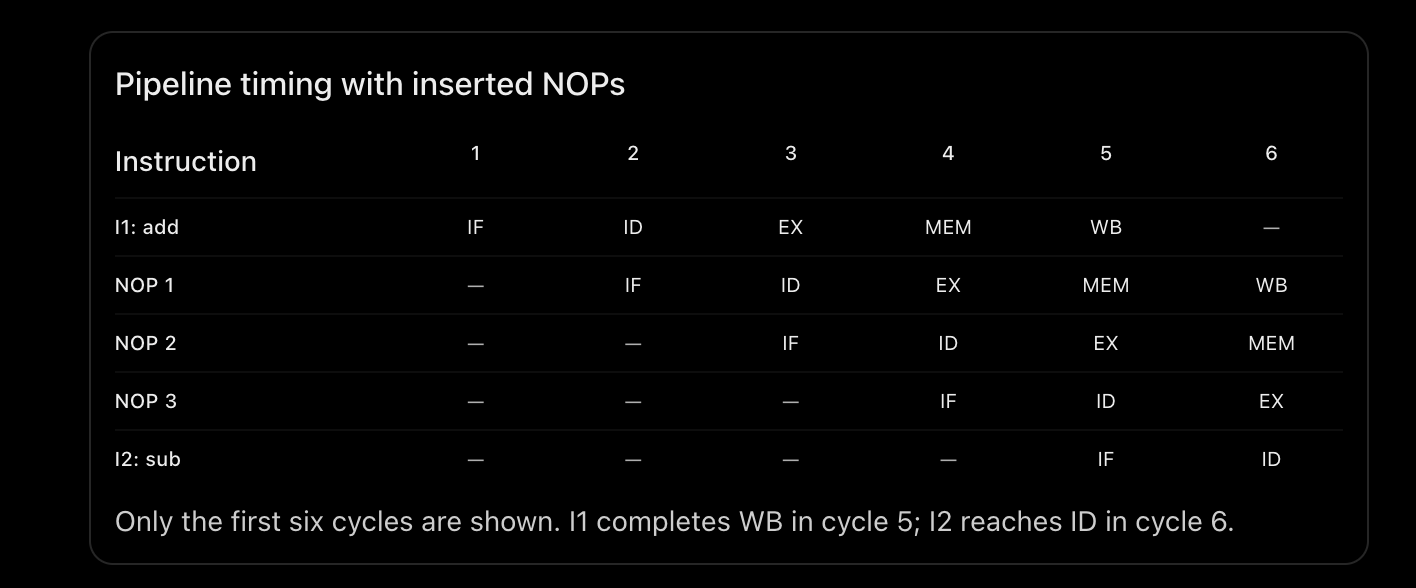

Only the first six cycles are shown.

- `I1` completes WB in cycle 5.
- `I2` reaches ID in cycle 6.

### 1.5 Does Inserting NOPs Improve Performance?

**No.** It prevents incorrect execution, but the three NOP instructions still occupy pipeline slots.

For a long instruction sequence with one such RAW dependency:

- Without handling the hazard, execution might be incorrect.
- With a three-cycle hardware stall, we lose three cycles.
- With three NOPs, we spend three cycles processing useless instructions.

The professor gives a simple example of **seven useful instructions**.

With three additional NOPs, approximately ten instruction slots are consumed.

Useful IPC becomes:

$$
IPC=\frac{7}{10}=\boxed{0.7}
$$

The point is that NOP insertion ensures correctness but **does not recover the lost throughput**.

> 📌 This calculation ignores pipeline filling and draining, consistent with the professor's steady-state illustration.

---

## Part 2 — Software Solution: Instruction Scheduling

**Professor's Transcript:** Approximately 16:04–29:58

Now comes the smarter solution.

Rather than inserting three useless instructions, can we find **three useful, independent instructions** and execute them between `I1` and `I2`?

### 2.1 Original Program

Suppose the original program is:

```asm
I1: add x1, x2, x3
I2: add x4, x1, x5
I3: add x7, x8, x9
I4: add x10, x11, x12
I5: add x13, x14, x15
```

`I2` depends on `I1`.

But `I3`, `I4` and `I5` are independent of those instructions, assuming no other relevant dependencies or side effects.

### 2.2 Reordered Program

We can reorder the program:

```asm
I1: add x1, x2, x3
I3: add x7, x8, x9
I4: add x10, x11, x12
I5: add x13, x14, x15
I2: add x4, x1, x5
```

Now we have **three useful instructions between the producer and consumer**.

### 2.3 Compare the Two Solutions

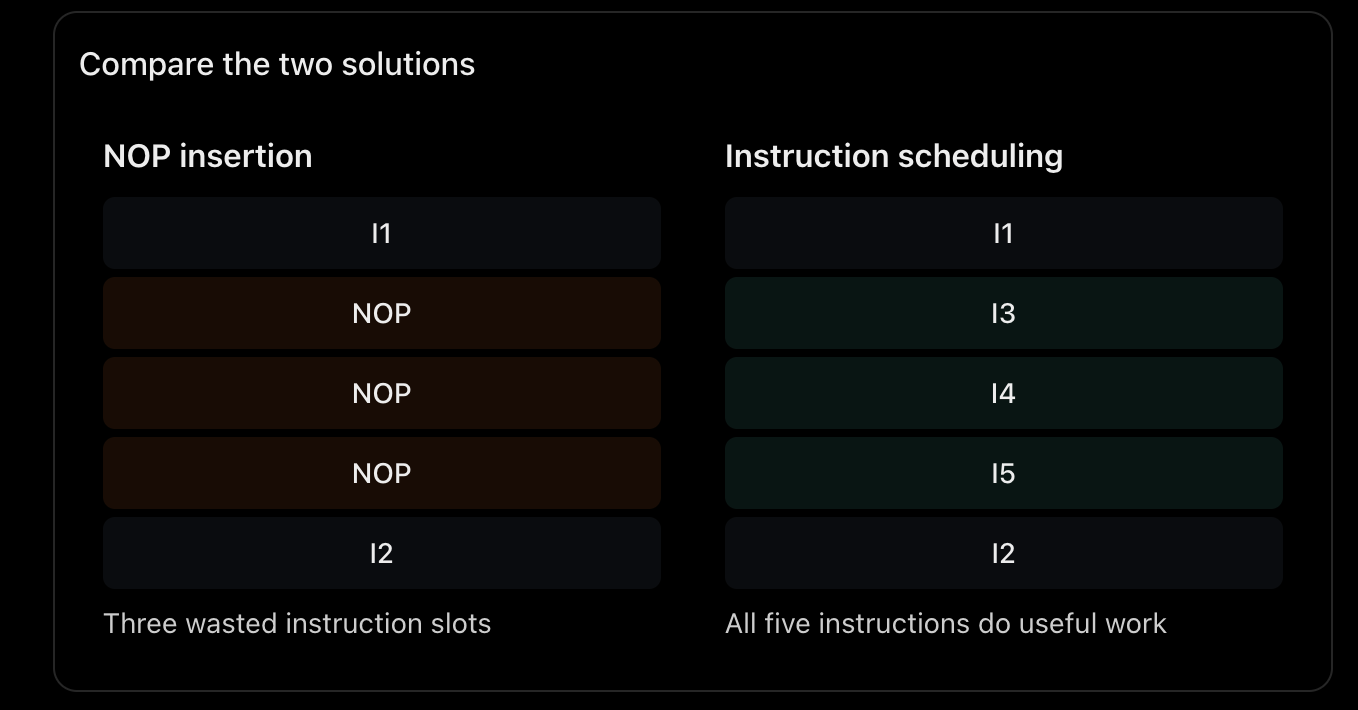

**NOP Insertion:**

```text
I1
↓
NOP
↓
NOP
↓
NOP
↓
I2
```

**Three wasted instruction slots.**

**Instruction Scheduling:**

```text
I1
↓
I3
↓
I4
↓
I5
↓
I2
```

**All five instructions do useful work.**

### 2.4 Why Is Instruction Scheduling Better?

Because it fills otherwise wasted pipeline slots with useful work.

Using the professor's steady-state example of seven useful instructions:

| Strategy | Useful Instructions | Instruction Slots Used | Useful IPC |
|---|---|---|---|
| NOP insertion | 7 | 10 | 0.7 |
| Successful scheduling | 7 | 7 | **1.0** |

### 2.5 Who Performs This Rearrangement?

Usually the **compiler**, subject to the processor's dependency and scheduling rules.

But there's an important restriction:

**The compiler cannot move arbitrary instructions.**

It must preserve the original program's observable behavior.

For example, the professor gives an instruction that writes the same destination as another instruction.

Moving it could introduce **WAW ordering problems**.

Therefore, instruction scheduling is possible only when the rearrangement preserves:

- Data dependencies
- Control dependencies
- Relevant side effects

### Exam Definition

> **Instruction Scheduling:** A software technique for reducing pipeline stalls by rearranging independent instructions while preserving program semantics.

---

## Part 3 — Why Software Solutions Have Limitations

The professor identifies an important disadvantage.

To schedule instructions optimally, the compiler must know details of the processor's execution architecture, including:

- Pipeline depth and stage timing.
- Instruction latency.
- Availability of forwarding.
- Required spacing between dependent instructions.

If the compiler assumes a **three-cycle RAW penalty** but the target processor has a different pipeline design, its schedule may be inefficient.

Also, sufficient independent instructions may not exist to fill every delay slot.

This motivates **hardware-based hazard detection and resolution**.

The remaining part of Lecture 25 introduces two detection mechanisms:

1. **Scoreboarding**
2. **Combinational dependency-check logic**

Lecture 26 then develops **data forwarding** as a hardware solution.

---



# Lecture 25 — Part 3: Detecting RAW Hazards in Hardware

**Professor:** Dr. Janibul Bashir  
**Transcript:** Approximately 30:00–56:38

The professor introduces two hardware mechanisms to detect dependencies:

1. **Scoreboarding**
2. **Combinational dependency-check logic**

> 📌 **Important distinction:**
>
> - **Hazard detection:** Tells the processor when an instruction has a dependency.
> - **Hazard resolution:** Tells the processor what to do about that dependency.

For example, after detecting RAW, the processor could stall the dependent instruction or use forwarding if the necessary hardware exists.

---

## 1. Scoreboarding — Why Do We Need It?

Consider:

```asm
I1: add x3, x4, x5
I2: add x6, x3, x7
```

`I1` generates the value of `x3`.

`I2` needs that value.

So the processor needs a mechanism to recognize:

> Register `x3` has a pending write, so its new value isn't ready to be read yet.

The professor's solution is to associate a **valid bit** with each register.

### 1.1 Register Scoreboard

**Register scoreboard after I1 enters the pipeline:**

| Register | Valid Bit | Meaning |
|---|---|---|
| `x1` | 1 | Available |
| `x2` | 1 | Available |
| `x3` | **0** | **Pending write from I1** |
| `x4` | 1 | Available |
| `x5` | 1 | Available |
| `x6` | 1 | Available |
| `x7` | 1 | Available |

The meaning is:

$$
Valid[x]=
\begin{cases}
1 & \text{Register value is available}\\
0 & \text{Register has a pending result}
\end{cases}
$$

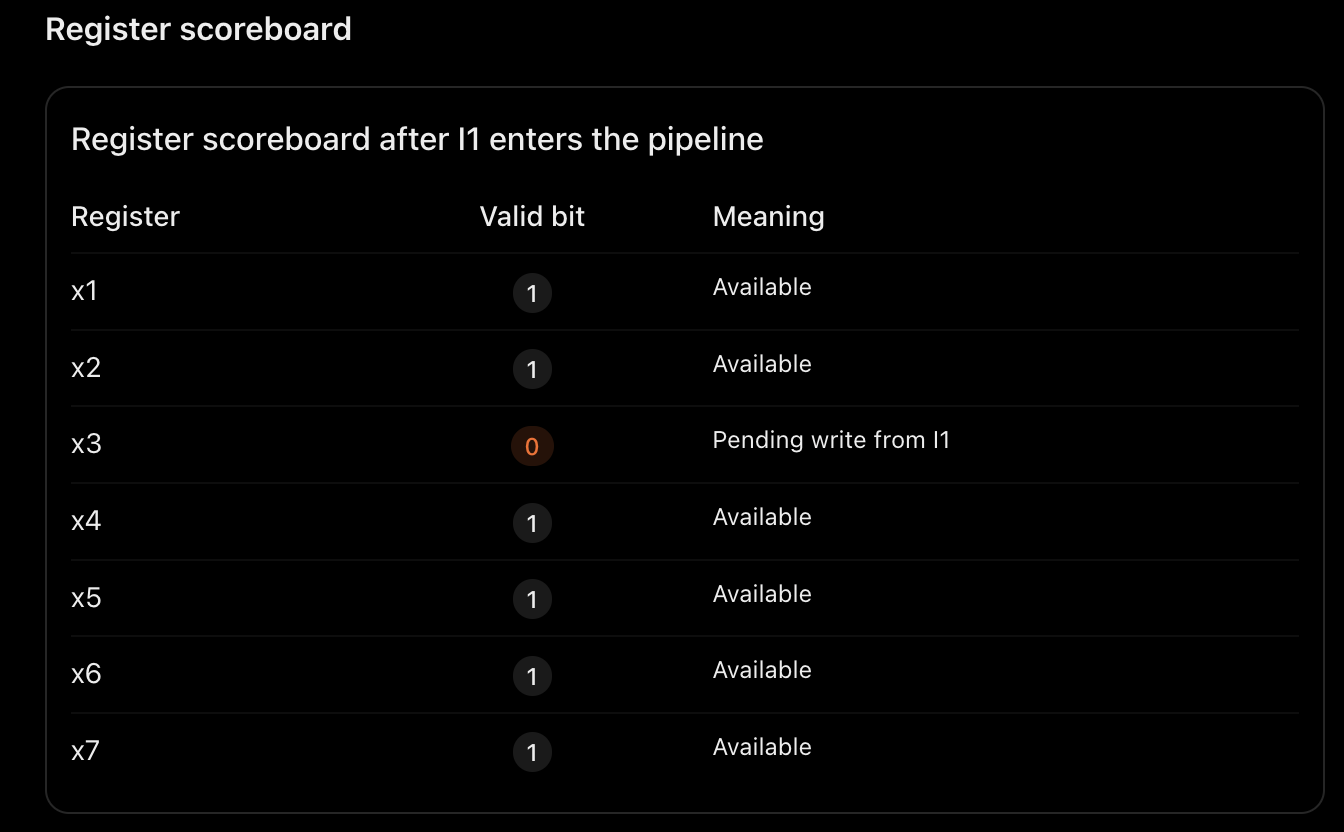
### 1.2 How Does Scoreboarding Work?

Let's dry-run the professor's example.

#### Step 1 — Initially, All Registers Are Valid

For simplicity:

```text
Valid[x3] = 1
Valid[x4] = 1
Valid[x5] = 1
```

#### Step 2 — I1 Enters the Pipeline

```asm
add x3, x4, x5
```

The processor marks its destination as pending:

$$
\boxed{Valid[x3]=0}
$$

Because I1 hasn't written the new result to `x3` yet.

#### Step 3 — I2 Is Fetched

```asm
add x6, x3, x7
```

The processor checks its source registers:

- `Valid[x3] = 0`
- `Valid[x7] = 1`

Since `x3` isn't available, I2 must wait.

#### Step 4 — I1 Completes WB

I1 writes its result into `x3`.

The processor updates:

$$
\boxed{Valid[x3]=1}
$$

Now I2 can read the correct value and proceed.

### Exam Definition

> **Scoreboarding:** A hardware technique that tracks the availability and dependencies of operands or functional units to determine when instructions can safely execute.

The professor uses a simplified **one-valid-bit-per-register scoreboard**.

More sophisticated scoreboards maintain additional state.

---

## 2. The Limitation of the Professor's Initial Scoreboard

**Transcript:** Approximately 46:17–49:04

Let's examine two instructions:

```asm
I1: add x3, x4, x5
I2: sub x3, x6, x7
```

### 2.1 What Dependency Is Present?

Both instructions write into `x3`.

Therefore:

$$
\boxed{WAW}
$$

Now imagine that the simplified scoreboard checks every register named in I2, including its destination.

- I1 has marked `x3` invalid.
- I2 also names `x3`.
- The scoreboard might unnecessarily stall I2.

But in our simple in-order, five-stage pipeline, the two writes naturally occur in program order.

This WAW relationship does not require a stall.

### 2.2 Professor's Improvement

Instead of checking all register fields, check only the **actual source operands** of the waiting instruction.

For I2:

```asm
sub x3, x6, x7
```

The source registers are:

- `x6`
- `x7`

Both are valid.

So I2 can proceed.

This avoids incorrectly identifying WAW as a RAW hazard.

### 2.3 Essential Logic

$$
\boxed{
RAW\_Hazard=
\neg Valid[rs1]\lor\neg Valid[rs2]
}
$$

> 📝 **Clarification:** This expression assumes the instruction actually uses both source fields. Instructions such as `addi` or `lui` require appropriate source-use checks.

Also, the simple valid-bit mechanism must be extended if multiple outstanding writes to a register are permitted.

Otherwise, an earlier completion could incorrectly mark a value ready while a younger write remains pending.

---

## 3. Combinational Dependency-Check Logic

**Professor's Transcript:** Approximately 49:19–56:38

Now the professor introduces another approach.

Instead of maintaining valid bits, why not directly compare the registers used by the instructions currently in the pipeline?

We know a RAW dependency exists when:

$$
\boxed{
\text{Source register of younger instruction}
=
\text{Destination register of older instruction}
}
$$

### 3.1 Five-Stage Pipeline

```text
IF → ID → EX → MEM → WB
```

Suppose the instruction currently in ID wants to read:

- `rs1`
- `rs2`

We compare those source registers with the destination registers of older instructions in:

- EX
- MEM
- WB

### 3.2 Conceptual Dependency-Check Circuit

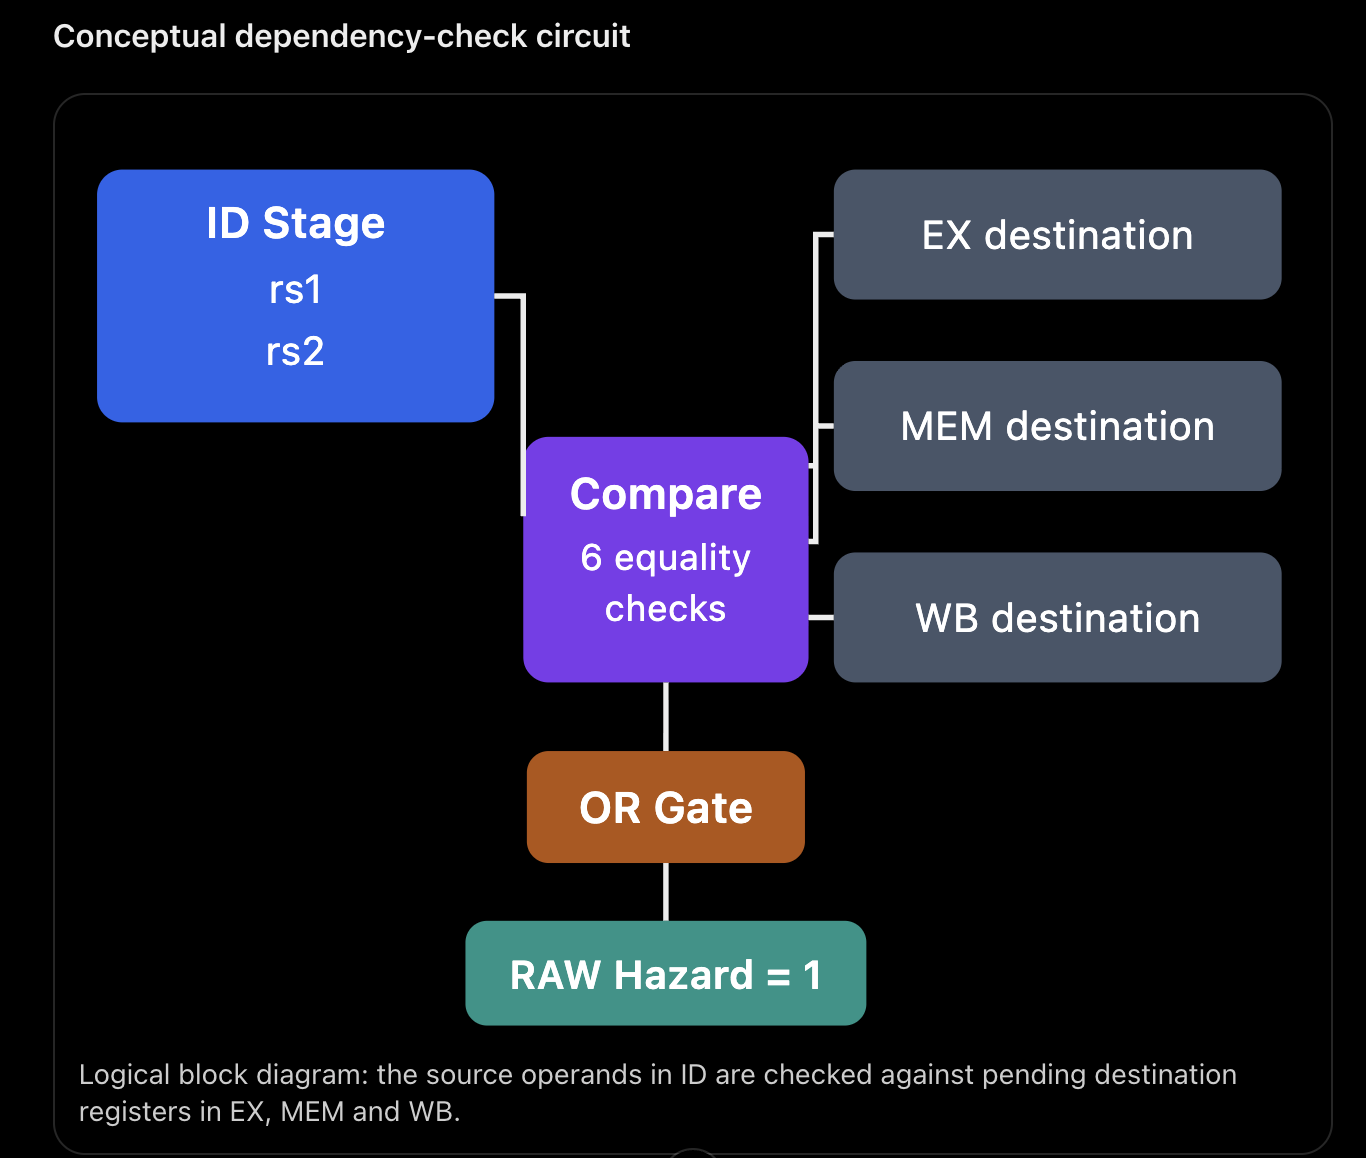

*Logical block diagram: The source operands in ID are checked against pending destination registers in EX, MEM and WB.*

### 3.3 How Many Comparisons Are Needed?

There are:

- **2 source registers:** `rs1`, `rs2`.
- **3 older pipeline stages:** EX, MEM, WB.

Thus:

$$
\boxed{2\times3=6\text{ comparisons}}
$$

They are:

| Source | Compare Against |
|---|---|
| `ID.rs1` | `EX.rd` |
| `ID.rs1` | `MEM.rd` |
| `ID.rs1` | `WB.rd` |
| `ID.rs2` | `EX.rd` |
| `ID.rs2` | `MEM.rd` |
| `ID.rs2` | `WB.rd` |

If any applicable comparison matches, the circuit asserts a **RAW-hazard signal**.

### 3.4 Boolean Expression

Let $E$, $M$, and $W$ denote the destination registers of instructions in EX, MEM and WB.

Then, in the professor's simplified model:

$$
\begin{aligned}
RAW ={}&
(rs1=E)\lor(rs1=M)\lor(rs1=W)\\
&\lor(rs2=E)\lor(rs2=M)\lor(rs2=W)
\end{aligned}
$$

Each equality comparison produces a **one-bit result**.

The OR logic combines the six results.

If any comparison is true:

$$
RAW=1
$$

Otherwise:

$$
RAW=0
$$

> 📝 **Practical clarification:** A practical circuit also checks that the older instruction will write a register, that its destination isn't `x0`, and that the younger instruction actually reads the relevant source register.

---

## 4. Dry Run of the Hardware Detector

Consider:

```asm
I1: add x5, x1, x2
I2: sub x6, x3, x4
I3: add x7, x5, x8
```

Suppose at a particular moment:

| Stage | Instruction |
|---|---|
| EX | I1 |
| ID | I2 |
| IF | I3 |

### 4.1 Does I2 Have a RAW Dependency on I1?

I2 reads:

- `x3`
- `x4`

I1 writes:

- `x5`

Neither source matches `x5`.

$$
RAW=0
$$

So I2 can proceed.

### 4.2 What Happens When I3 Reaches ID?

I3 reads:

$$
rs1=x5,\qquad rs2=x8
$$

If I1 is still in a stage with a pending write to `x5`, the comparison detects:

$$
rs1(I3)=rd(I1)=x5
$$

Therefore:

$$
\boxed{RAW=1}
$$

The hazard detector instructs the pipeline-control logic to delay I3 until the required value becomes available.

---

## 5. Scoreboarding vs Combinational Logic

| Feature | Scoreboarding | Combinational Dependency Check |
|---|---|---|
| Main idea | Track register readiness | Compare register identifiers |
| Hardware | Readiness bits/state | Comparators and OR gates |
| Detects dependency using | Pending-result status | Source/destination matches |
| When updated | On issue and result availability | Continuously from current pipeline state |
| Professor's example | One valid bit per register | Six comparisons |
| Limitation | Needs correct readiness bookkeeping | Must account for writing, source use, and result timing |

### Important Distinction

> 📌 These are **detection techniques**. Detecting a RAW dependency does not automatically resolve it.

Once detected, the processor can:

- Stall the dependent instruction.
- Use forwarding.
- Apply another appropriate mechanism.

Lecture 26 focuses on **data forwarding**, which reduces the cost of RAW hazards.

---

## 6. Lecture 25 — Exam-Ready Revision

The professor's main results are:

### Software Solution 1 — NOP Insertion

Insert NOPs between dependent instructions.

Correctness improves, but no useful performance is recovered.

### Software Solution 2 — Instruction Scheduling

Reorder independent instructions.

Useful work replaces stalls, improving IPC.

### Hardware Detection 1 — Scoreboarding

Maintain readiness information for registers to identify pending dependencies.

### Hardware Detection 2 — Combinational Logic

Compare the source registers of the instruction in ID against pending destination registers of older instructions in EX, MEM and WB.

### Hardware Resolution

Once dependencies are detected, stall or use forwarding.

**Data forwarding is the subject of Lecture 26.**

---


# DOUBTS :

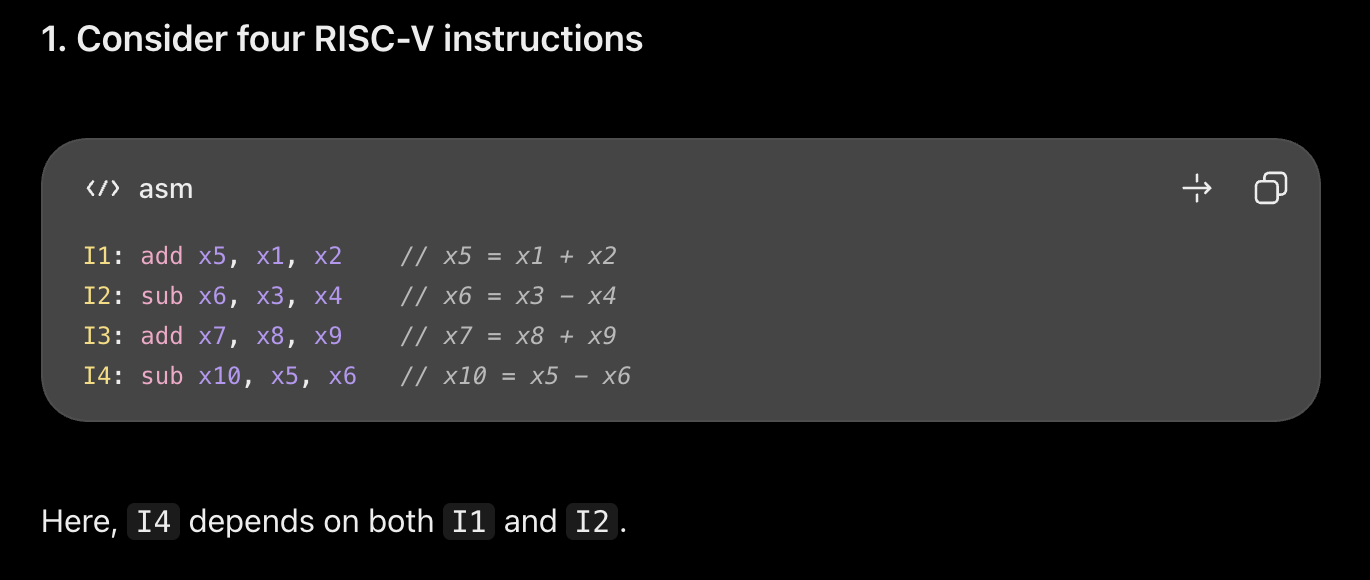
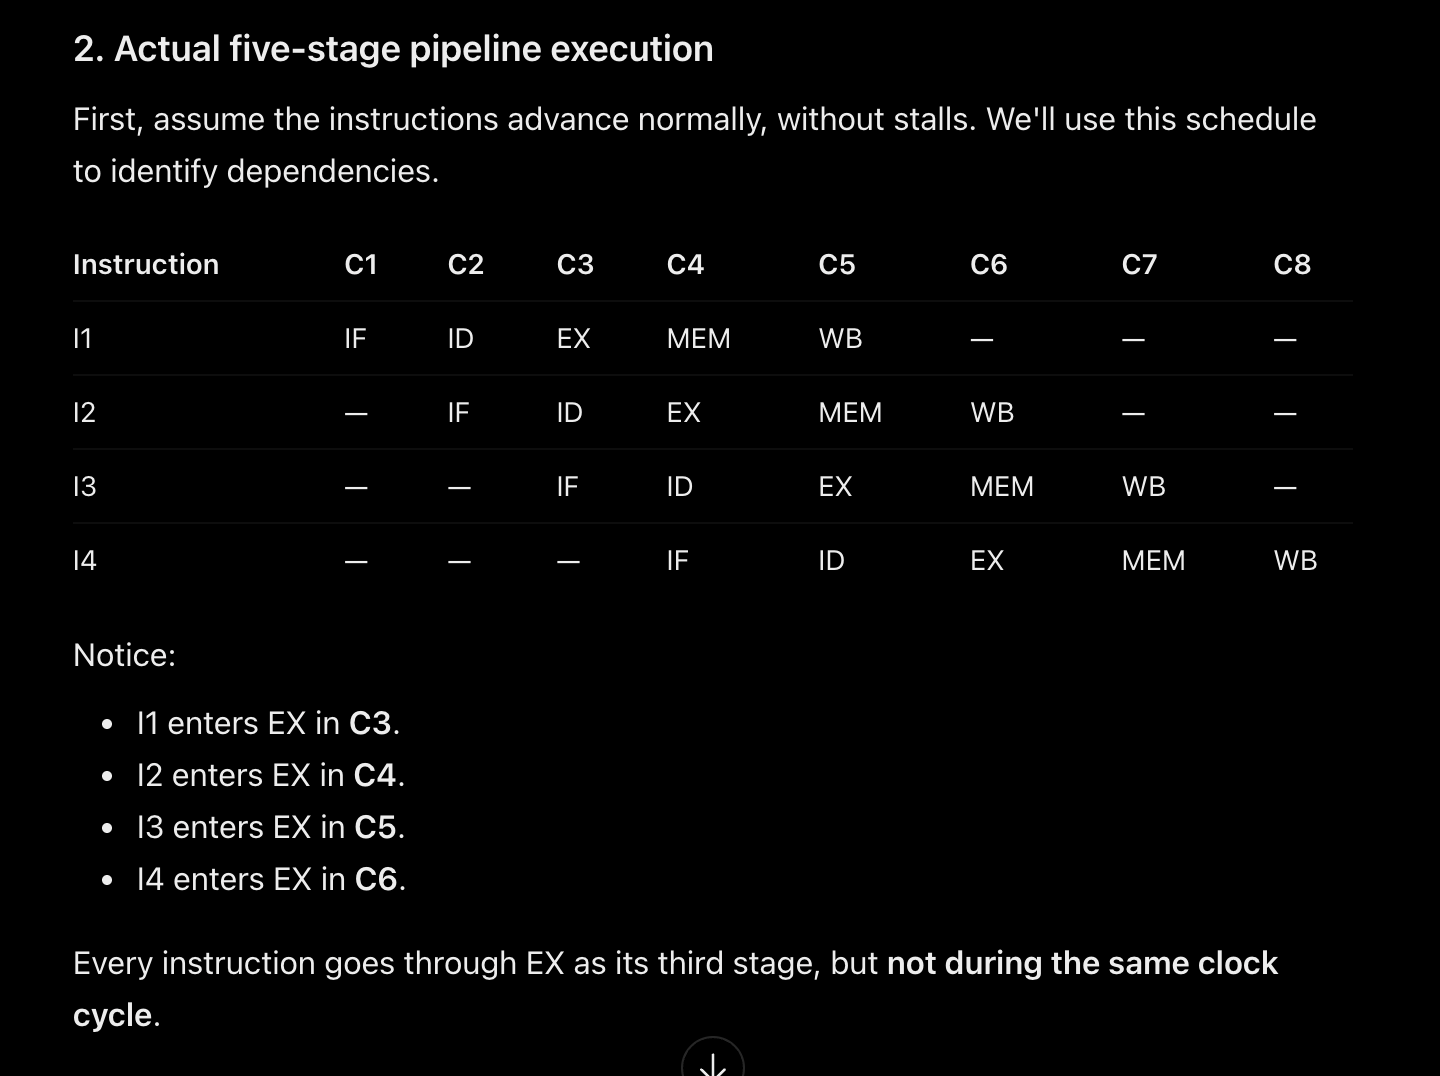
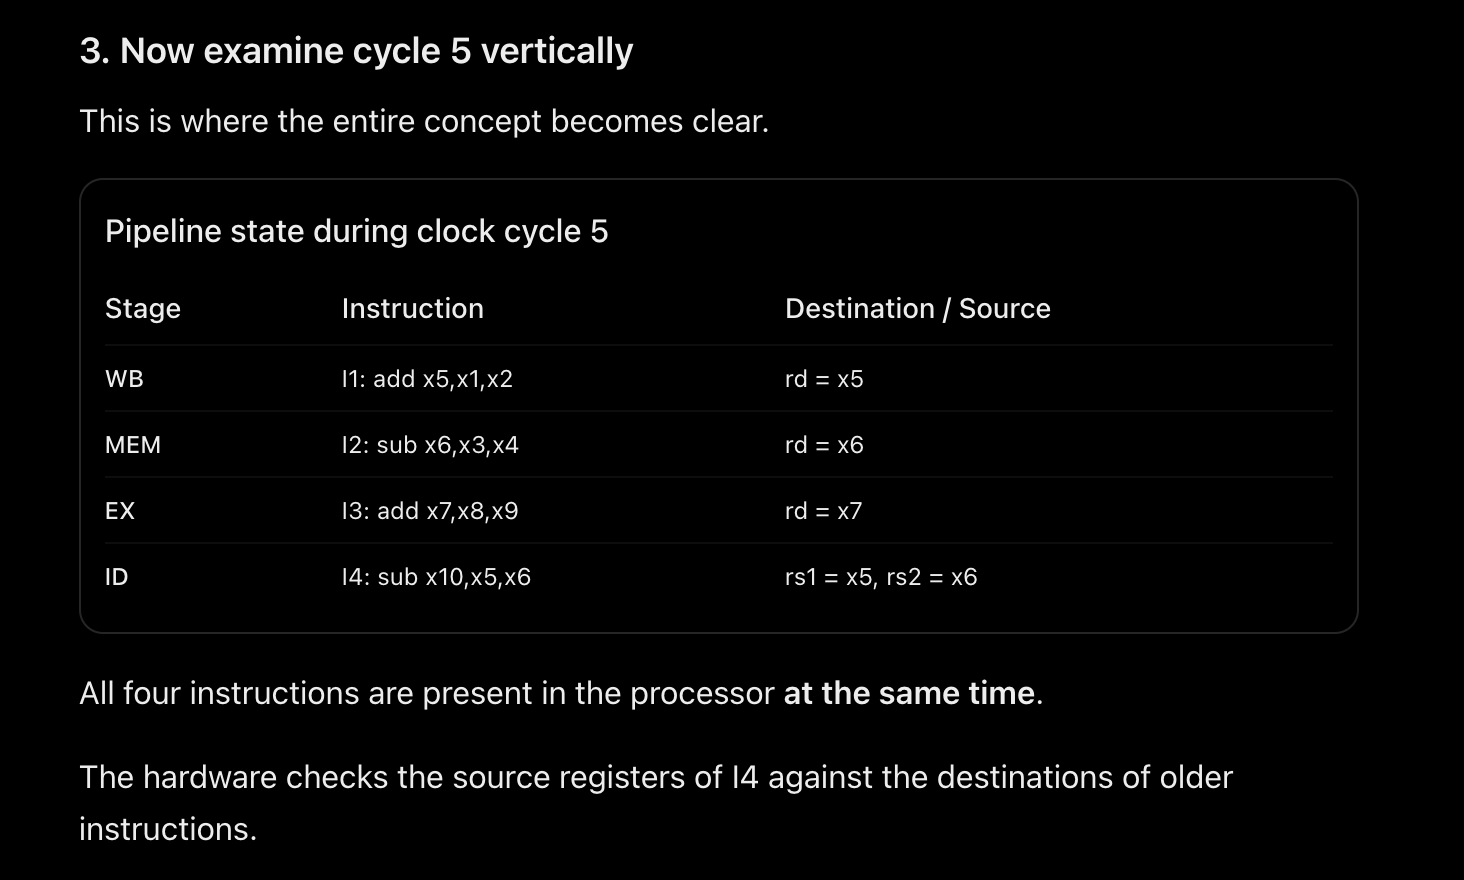

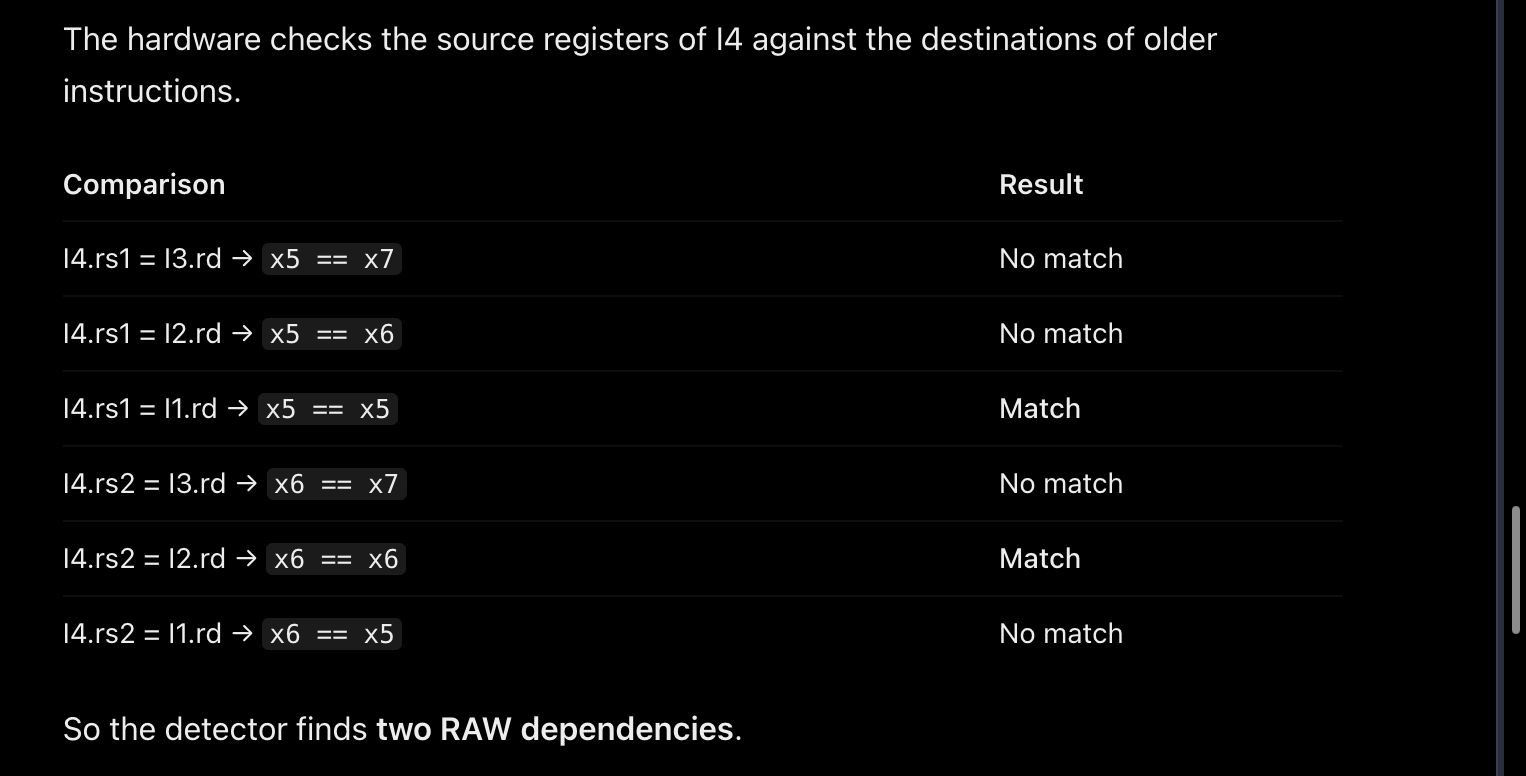

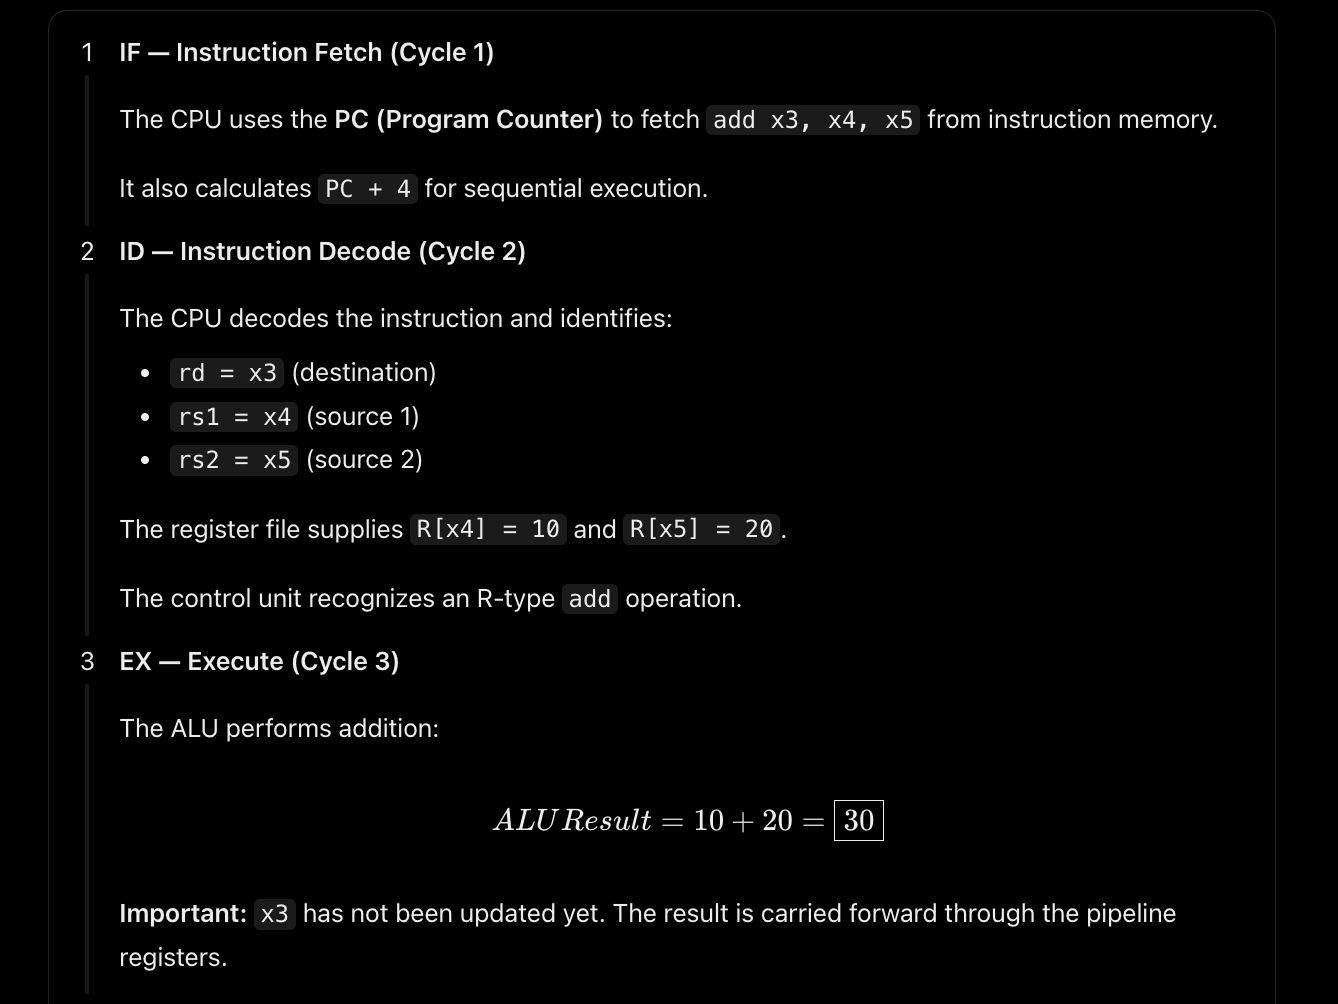
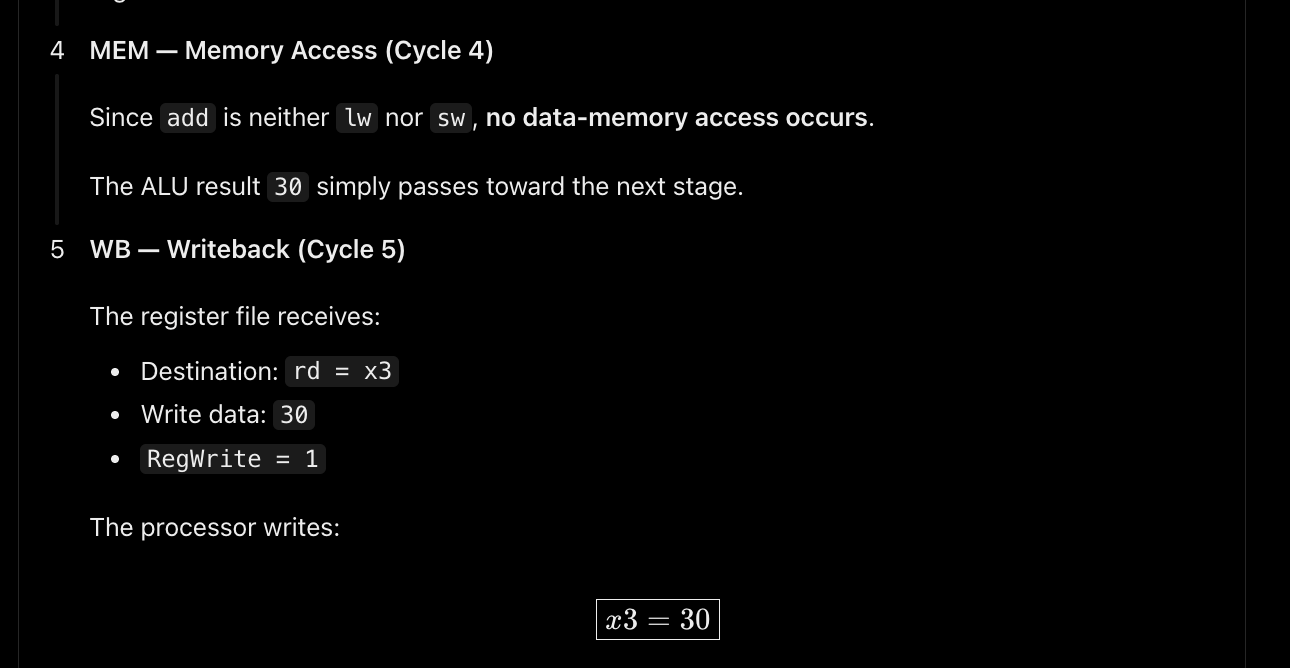
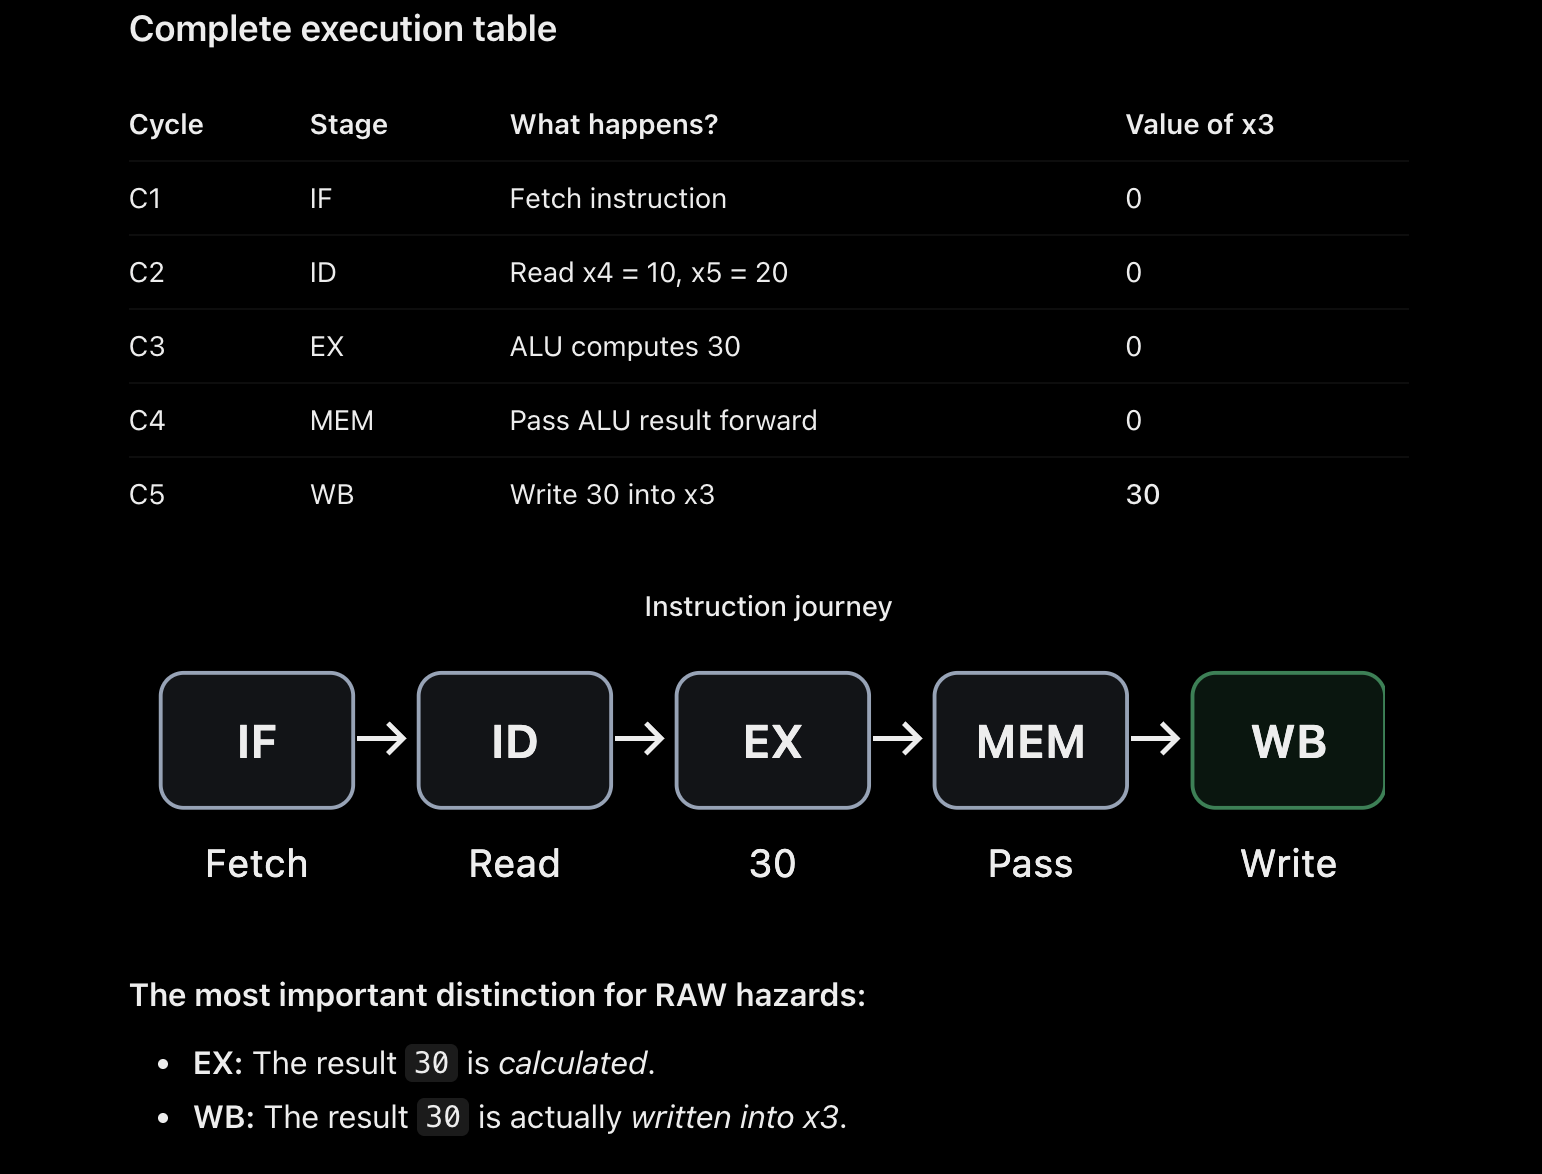